# 購買履歴から顧客を分類する：k-meansとGMM

## 概要

同じ案内を全顧客に送っても、初回購入の顧客と繰り返し購入する顧客では、必要な情報が異なる。本記事では、[『マーケティングサイエンスの理論と実践』](https://gihyo.jp/book/2026/978-4-297-16025-8)の第2章「顧客を分類する」を紹介する。総支出額と注文回数から顧客の違いを整理し、k-meansと混合ガウスモデル（GMM）の結果を施策の検討につなげる。

本文と同じ実データを使い、前処理、分類、所属確率の確認までをPythonで計算する。分類によって施策の効果がわかるわけではなく、対象者や検証する施策を考えるための分析である。

### 実行環境

仮想環境は **wa-src(3.14.6)**、Pythonは **3.14.6** である。NumPy、pandas、SciPy、scikit-learn、Matplotlibを使う。以下は上から順に実行する。配布用ZIPの`data`フォルダには入力データを同梱し、生成した図は`02_nb_files`にSVG形式で保存する。小数は有効数字3桁で表示し、計算には丸める前の値を使う。

In [1]:
from pathlib import Path
from pprint import pprint
from importlib.metadata import version
from io import BytesIO
from base64 import b64encode
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Ellipse
from matplotlib.ticker import FuncFormatter, MaxNLocator, ScalarFormatter
from scipy.stats import chi2
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from IPython.display import Latex, display

# ノートブックのあるディレクトリ、またはリポジトリ直下から実行する。
BASE = Path.cwd()
if (BASE / "blog/02/02_nb.ipynb").exists():
    BASE = BASE / "blog/02"
FIG_DIR = BASE / "02_nb_files"
FIG_DIR.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロを残し、小数を有効数字3桁で表示する。"""
    return format(float(value), "#.3g").removesuffix(".")


def show_math(tex):
    # 重要式は \( ... \) で記述し、表示時に外側の区切りを取り除く。
    # 出力用の $$ ... $$ と二重に囲まないようにする。
    tex = tex.strip()
    if tex.startswith(r"\(") and tex.endswith(r"\)"):
        tex = tex[2:-2].strip()
    display(Latex("$$\n" + tex + "\n$$"))


def save_svg(fig, filename):
    """同じSVGをファイルとノートブック出力の両方に保存する。"""
    # 自動目盛りも、小数が現れる場合は有効数字3桁にそろえる。
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                axis.set_major_formatter(FuncFormatter(
                    lambda value, _: str(int(value)) if float(value).is_integer() else sig3(value)
                ))
    path = FIG_DIR / filename
    fig.savefig(path, format="svg", bbox_inches="tight")
    # SVGを表示できない閲覧環境向けに、PNGも出力欄だけに埋め込む。
    preview = BytesIO()
    fig.savefig(preview, format="png", dpi=120, bbox_inches="tight")
    plt.close(fig)
    display({"image/svg+xml": path.read_text(encoding="utf-8"),
             "image/png": b64encode(preview.getvalue()).decode("ascii")}, raw=True,
            metadata={"image/svg+xml": {"width": min(860, int(fig.get_figwidth() * 96))},
                      "image/png": {"width": min(860, int(fig.get_figwidth() * 96))}})


np.set_printoptions(formatter={"float_kind": sig3})
pd.options.display.float_format = sig3
fonts = {font.name for font in font_manager.fontManager.ttflist}
for candidate in ("Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "Yu Gothic"):
    if candidate in fonts:
        plt.rcParams["font.family"] = candidate
        break
plt.rcParams.update({"font.size": 11, "axes.unicode_minus": False,
                     "svg.fonttype": "path", "svg.hashsalt": "blog02"})
tick3 = FuncFormatter(lambda value, _: sig3(value))
colors = ["#3274A1", "#D58B27", "#419578", "#9D5F95"]

print("仮想環境：wa-src(3.14.6)")
print(f"Python：{platform.python_version()}")
for package in ("numpy", "pandas", "scipy", "scikit-learn", "matplotlib"):
    print(f"{package}：{version(package)}")

仮想環境：wa-src(3.14.6)
Python：3.14.6
numpy：2.5.4
pandas：3.1.1
scipy：1.18.1
scikit-learn：1.9.1
matplotlib：3.11.2


## 1. どの顧客に、何を案内するか

本章の出発点は、年齢や性別が同じでも購買行動は異なるという点にある。STPは、顧客を分けるSegmentation、重点対象を選ぶTargeting、伝える価値を決めるPositioningを指す。ここでは、まず購買履歴で顧客を分ける。

使用するのは[UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail)である。英国のオンライン小売事業者の、2010年12月から2011年12月までの取引を含む。顧客IDがあり、数量と単価が正の明細だけを残すと、分析対象は4,338顧客になる。

総支出額は「数量×単価」の合計、注文回数は請求書番号の重複を除いた件数とする。返品・キャンセル分を差し引いた純売上ではない。以下で顧客ごとの2列を作る。

In [2]:
# 書籍のCSVを読み込み、取引明細を1行1顧客に集計する。
raw = pd.read_csv(
    BASE / "data/online_retail.csv.gz",
    usecols=["CustomerID", "InvoiceNo", "Quantity", "UnitPrice"],
    dtype={"CustomerID": "Int64", "InvoiceNo": "string"},
)
retail = raw.loc[
    raw["CustomerID"].notna() & (raw["Quantity"] > 0) & (raw["UnitPrice"] > 0)
].copy()
retail["amount"] = retail["Quantity"] * retail["UnitPrice"]
customers = retail.groupby("CustomerID", sort=True).agg(
    spend=("amount", "sum"),
    orders=("InvoiceNo", "nunique"),
)
print(f"分析対象：{len(customers):,}顧客")
print("spend：総支出額（GBP）、orders：注文回数")
print(customers.head().to_string())

分析対象：4,338顧客
spend：総支出額（GBP）、orders：注文回数
              spend  orders
CustomerID                 
12346      7.72e+04       1
12347      4.31e+03       7
12348      1.80e+03       4
12349      1.76e+03       1
12350           334       1


## 2. 金額と回数を、そのまま距離にしない

総支出額と注文回数は単位も値の範囲も異なる。そのまま距離を計算すると、金額の差が強く影響する。また、大きな値を持つ顧客が少数いる。本章では各値に1を足して自然対数を取り、その後で平均0・分散1に標準化する。

$x_{ij}$を顧客$i$の特徴量$j$、$n$を顧客数とする。対数変換後の平均$\bar{u}_j$と標準偏差$s_j$を順に求め、標準化したベクトル$\mathbf{z}_i$を作る。分散の分母は、`StandardScaler`と同じ$n$である。

<IPython.core.display.Latex object>

標準化した先頭3顧客（列順：総支出額、注文回数）
array([[3.71, -0.955],
       [1.41, 1.07],
       [0.716, 0.386]])


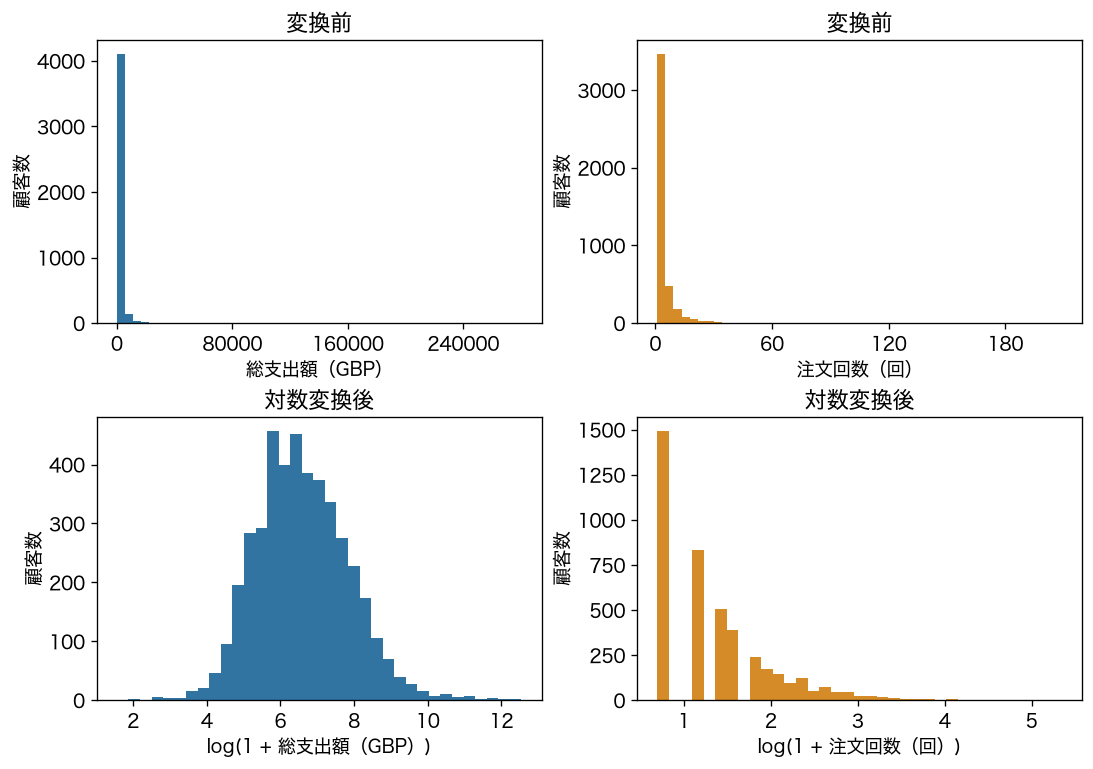

In [3]:
show_math(r"""\(
\begin{aligned}
u_{ij}&=\log(1+x_{ij}), &
\bar{u}_j&=\frac{1}{n}\sum_{i=1}^{n}u_{ij},\\
s_j^2&=\frac{1}{n}\sum_{i=1}^{n}(u_{ij}-\bar{u}_j)^2, &
s_j&=\sqrt{s_j^2},\\
z_{ij}&=\frac{u_{ij}-\bar{u}_j}{s_j}, &
\mathbf{z}_i&=(z_{i1},z_{i2}).
\end{aligned}
\)""")

values = customers[["spend", "orders"]].to_numpy(dtype=float)
log_values = np.log1p(values)
scaler = StandardScaler()
Z = scaler.fit_transform(log_values)
print("標準化した先頭3顧客（列順：総支出額、注文回数）")
pprint(Z[:3])

# 上段は元の単位、下段は対数変換後。全顧客を表示する。
fig, axes = plt.subplots(2, 2, figsize=(9, 6.30), layout="constrained")
for j, name in enumerate(("総支出額（GBP）", "注文回数（回）")):
    axes[0, j].hist(values[:, j], bins=50, color=colors[j])
    axes[0, j].set(xlabel=name, ylabel="顧客数", title="変換前")
    axes[1, j].hist(log_values[:, j], bins=35, color=colors[j])
    axes[1, j].set(xlabel=f"log(1 + {name})", ylabel="顧客数", title="対数変換後")
    axes[0, j].xaxis.set_major_locator(MaxNLocator(4))
save_svg(fig, "01_distributions.svg")

図1の上段では少数の大口顧客に横軸が引き延ばされる。下段の対数変換後は、小口から大口までの分布を確認しやすい。対数変換は大きな値の差を縮め、標準化は特徴量の尺度をそろえる。役割は異なる。

顧客間の近さにはユークリッド距離を使う。計算だけを確かめる例として、$\mathbf{z}_A=(0,1)$、$\mathbf{z}_B=(2,2)$を置く。各座標の差を二乗し、足してから平方根を取る。これは実データの顧客ではない。

In [4]:
show_math(r"""\(
\begin{aligned}
d(\mathbf{z}_A,\mathbf{z}_B)
&=\sqrt{\sum_{j=1}^{2}(z_{Aj}-z_{Bj})^2}\\
&=\sqrt{(0-2)^2+(1-2)^2}\\
&=\sqrt{4+1}=\sqrt{5}\approx 2.24.
\end{aligned}
\)""")
example = np.array([[0, 1], [2, 2]])
pprint(sig3(np.linalg.norm(example[0] - example[1])))

<IPython.core.display.Latex object>

'2.24'


## 3. k-meansで購入規模の違いを整理する

k-meansは、各顧客を最も近い重心に割り当て、重心をそのクラスタの平均に更新する処理を繰り返す。目的は、重心からの二乗距離の合計SSEを小さくすることである。

$C_k$をクラスタ$k$の顧客集合、$n_k$をその人数、$\mathbf{c}_k$を重心とする。所属先を固定し、座標$c_{kj}$でSSEを微分すると、重心が平均になることを確認できる。

In [5]:
show_math(r"""\(
\begin{aligned}
\mathrm{SSE}&=\sum_{k=1}^{K}\sum_{i\in C_k}\|\mathbf{z}_i-\mathbf{c}_k\|^2\\
&=\sum_{k=1}^{K}\sum_{i\in C_k}\sum_{j=1}^{2}(z_{ij}-c_{kj})^2,\\
\frac{\partial\mathrm{SSE}}{\partial c_{kj}}
&=2\sum_{i\in C_k}(c_{kj}-z_{ij})\\
&=2n_kc_{kj}-2\sum_{i\in C_k}z_{ij}=0,\\
n_kc_{kj}&=\sum_{i\in C_k}z_{ij}
\quad\Longrightarrow\quad
\mathbf{c}_k=\frac{1}{n_k}\sum_{i\in C_k}\mathbf{z}_i.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

クラスタ数$K$は事前に指定する。エルボー法では、$K$を増やしたときのSSEの減り方を見る。SSEが最小になる数を選ぶ方法ではない。減少が緩やかになる位置を候補とし、施策を分ける意味があるかも確認する。

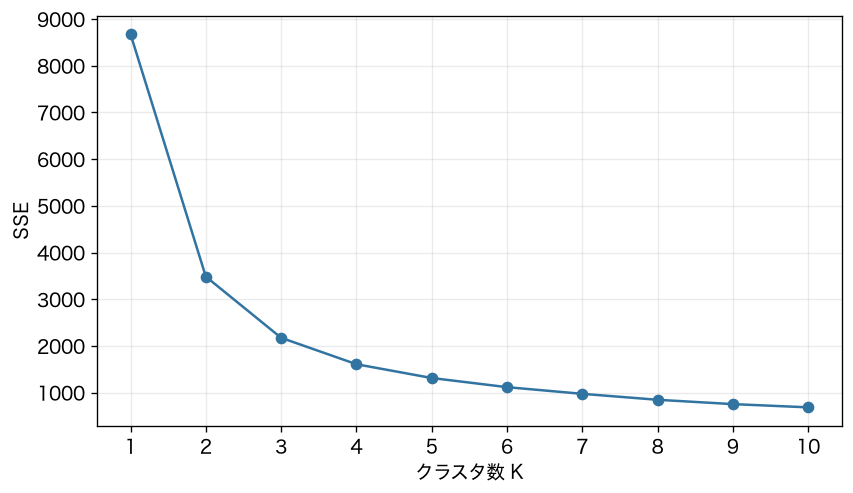

In [6]:
# 複数の初期値で学習し、各Kで最もSSEが小さい結果を使う。
models = {}
for k in range(1, 11):
    models[k] = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)
sse = np.array([model.inertia_ for model in models.values()])

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(range(1, 11), sse, "o-", color=colors[0])
ax.set(xlabel="クラスタ数 K", ylabel="SSE", xticks=range(1, 11))
ax.grid(alpha=0.250)
save_svg(fig, "02_elbow.svg")

# 本文と同じK=4を採用し、番号を購入規模の小さい順に並べ直す。
km = models[4]
order = np.argsort(scaler.inverse_transform(km.cluster_centers_).sum(axis=1))
mapping = np.empty(4, dtype=int)
mapping[order] = np.arange(4)
labels = mapping[km.labels_]
centers = km.cluster_centers_[order]
customers["segment"] = labels + 1

図2では$K=3$付近まで大きく下がり、その後は緩やかになる。本章では購入規模を4段階に分ける例として$K=4$を採用する。これは顧客の種類が本来4つであるという意味ではない。

分類後は元の単位に戻って特徴を読む。次の図は、左から顧客数、総支出額、注文回数である。点は中央値、線は第1四分位数から第3四分位数までを示す。

            n  spend_median  orders_median
segment                                   
1        1514           224           1.00
2        1456           708           2.00
3        1032      2.04e+03           6.00
4         336      6.41e+03           15.0


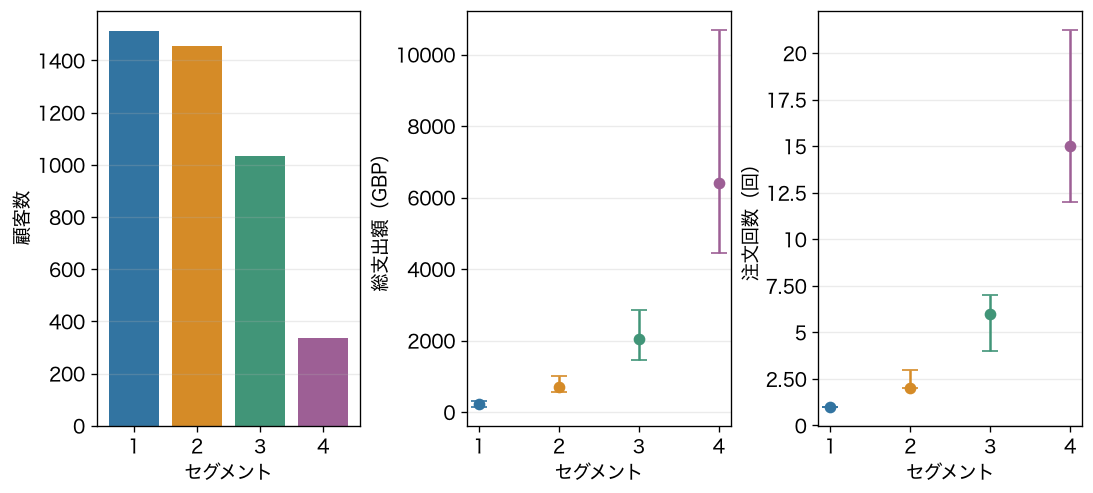

In [7]:
grouped = customers.groupby("segment")
summary = grouped.agg(n=("spend", "size"),
                      spend_median=("spend", "median"),
                      orders_median=("orders", "median"))
print(summary.to_string())

fig, axes = plt.subplots(1, 3, figsize=(9, 4), layout="constrained")
segments = np.arange(1, 5)
axes[0].bar(segments, summary["n"], color=colors)
axes[0].set(ylabel="顧客数")
for ax, feature, unit in zip(axes[1:], ("spend", "orders"), ("総支出額（GBP）", "注文回数（回）")):
    q = grouped[feature].quantile([0.250, 0.500, 0.750]).unstack()
    for k, color in zip(segments, colors):
        low, median, high = q.loc[k].to_numpy()
        ax.errorbar(k, median, yerr=[[median - low], [high - median]],
                    fmt="o", capsize=5, color=color)
    ax.set(ylabel=unit)
for ax in axes:
    ax.set(xlabel="セグメント", xticks=segments)
    ax.grid(axis="y", alpha=0.250)
save_svg(fig, "03_segment_profiles.svg")

低支出・単発中心の層は1,514人で、注文回数の中央値は1回である。高支出・高頻度の層は336人で、中央値は15.0回となった。私は、分類に名前を付ける前に、人数と元の単位の値を確認したい。少人数の大口顧客を「優良顧客」と呼ぶだけでは、どの施策が必要か判断できないからである。

## 4. GMMで分類の曖昧さも確認する

GMMは複数の正規分布を組み合わせ、各顧客の所属を確率で表す。$\pi_k$は成分の割合、$\mathbf{m}_k$は平均ベクトル、$\mathbf{S}_k$は広がりと向きを表す共分散行列である。$\mathcal{N}$は正規分布の確率密度を表す。

所属確率$\gamma_{ik}$は、成分$k$と顧客の特徴量の同時密度を、全成分を足した密度で割って求める。分子を$q_{ik}$と置くと、足して1になることも確認できる。

In [8]:
show_math(r"""\(
\begin{aligned}
q_{ik}&=\pi_k\mathcal{N}(\mathbf{z}_i\mid\mathbf{m}_k,\mathbf{S}_k),\\
p(\mathbf{z}_i)&=\sum_{j=1}^{K}q_{ij},\\
\gamma_{ik}&=\frac{p(k,\mathbf{z}_i)}{p(\mathbf{z}_i)}
=\frac{q_{ik}}{\sum_{j=1}^{K}q_{ij}},\\
\sum_{k=1}^{K}\gamma_{ik}&=\frac{\sum_{k=1}^{K}q_{ik}}{\sum_{j=1}^{K}q_{ij}}=1.
\end{aligned}
\)""")

# 所属確率の計算だけを示す仮の値。実データの推定結果ではない。
q_example = np.array([0.0800, 0.0200, 0.0900, 0.0100])
p_example = q_example / q_example.sum()
pprint(p_example)
show_math(r"""\(
\begin{aligned}
\sum_{j=1}^{4}q_{ij}&=0.0800+0.0200+0.0900+0.0100=0.200,\\
\gamma_{i3}&=\frac{0.0900}{0.200}=0.450,\\
\mathbf{p}_i&=(0.400,\ 0.100,\ 0.450,\ 0.0500),\\
1-\max_k\gamma_{ik}&=1-0.450=0.550.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

array([0.400, 0.100, 0.450, 0.0500])


<IPython.core.display.Latex object>

GMMの学習にはEMアルゴリズムを使う。現在の平均・共分散・割合から所属確率を計算し、その確率を重みとして各値を更新する処理を繰り返す。以下ではk-meansと比較するため、成分数を同じ4に固定する。

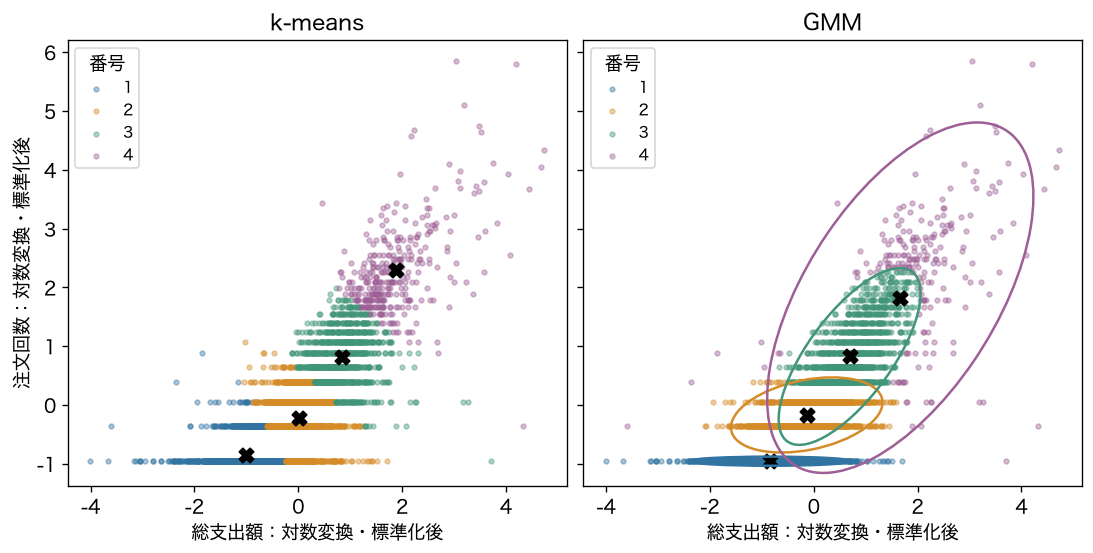

In [9]:
gmm = GaussianMixture(n_components=4, covariance_type="full",
                      n_init=20, random_state=42, reg_covar=0.00100).fit(Z)
gmm_order = np.argsort(scaler.inverse_transform(gmm.means_).sum(axis=1))
proba = gmm.predict_proba(Z)[:, gmm_order]
labels_gmm = proba.argmax(axis=1)
means = gmm.means_[gmm_order]
covariances = gmm.covariances_[gmm_order]
max_probability = proba.max(axis=1)

# 両手法を同じ軸・同じ範囲で比較する。
fig, axes = plt.subplots(1, 2, figsize=(9, 4.50), sharex=True, sharey=True,
                         layout="constrained")
for ax, assigned, center, title in zip(
    axes, (labels, labels_gmm), (centers, means), ("k-means", "GMM")
):
    for k, color in enumerate(colors):
        points = Z[assigned == k]
        ax.scatter(points[:, 0], points[:, 1], s=8, alpha=0.400,
                   color=color, label=str(k + 1))
    ax.scatter(center[:, 0], center[:, 1], marker="X", s=75, color="black")
    ax.set(title=title, xlabel="総支出額：対数変換・標準化後")
    ax.legend(title="番号", fontsize=9)
axes[0].set_ylabel("注文回数：対数変換・標準化後")

# GMMの各正規分布の95%確率楕円。推定平均の信頼区間ではない。
for mean, covariance, color in zip(means, covariances, colors):
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    width, height = 2 * np.sqrt(chi2.ppf(0.950, df=2) * eigenvalues)
    angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
    axes[1].add_patch(Ellipse(mean, width, height, angle=angle,
                             fill=False, edgecolor=color, linewidth=1.50))
save_svg(fig, "04_model_comparison.svg")

図4では、両手法とも購入規模に沿ってグループが並ぶ。GMMの楕円は、各正規分布の95%の確率を含む範囲であり、平均の信頼区間ではない。注文回数は整数なので、実際の点は水平な帯に並ぶ。正規分布による近似と、観測された点の並び方は一致しない。

次に各成分への所属確率を色で示す。境界では複数の成分に確率が分かれる。番号は各モデルで付け直しており、同じ番号でも所属する顧客は一致するとは限らない。

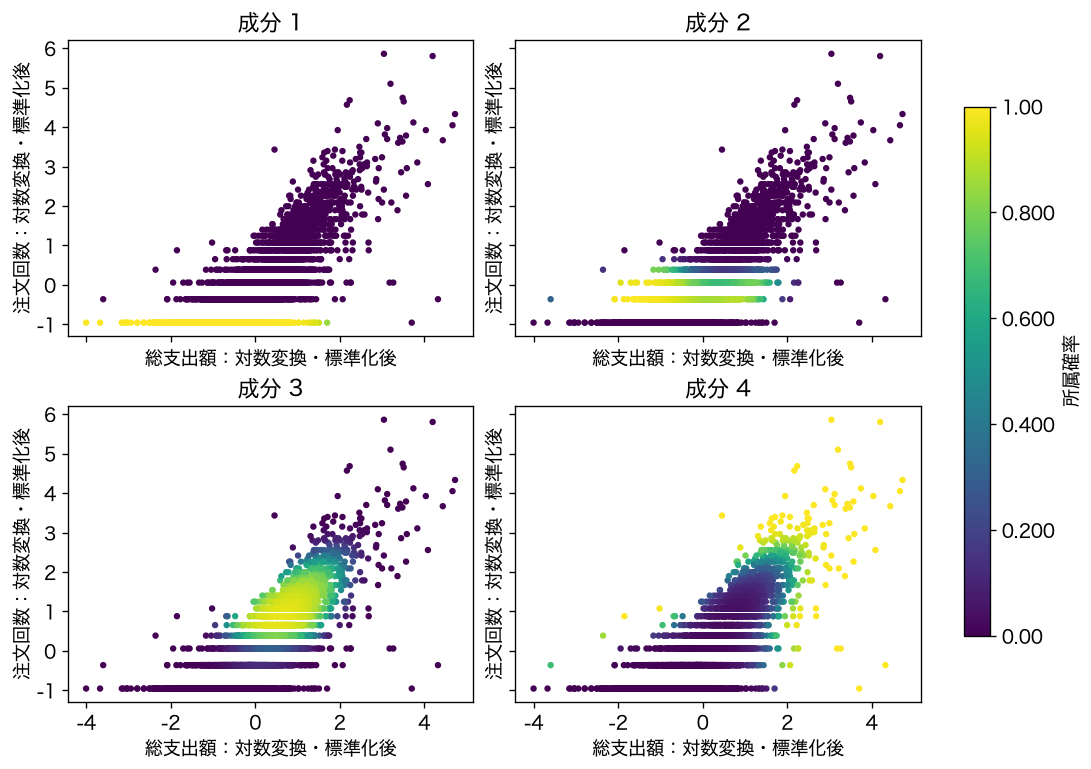

{'最大所属確率が0.800未満の割合（%）': '20.8', '最大所属確率の中央値': '0.944'}
分類が曖昧な1顧客の所属確率（成分1〜4）
array([0.00, 0.297, 0.372, 0.331])


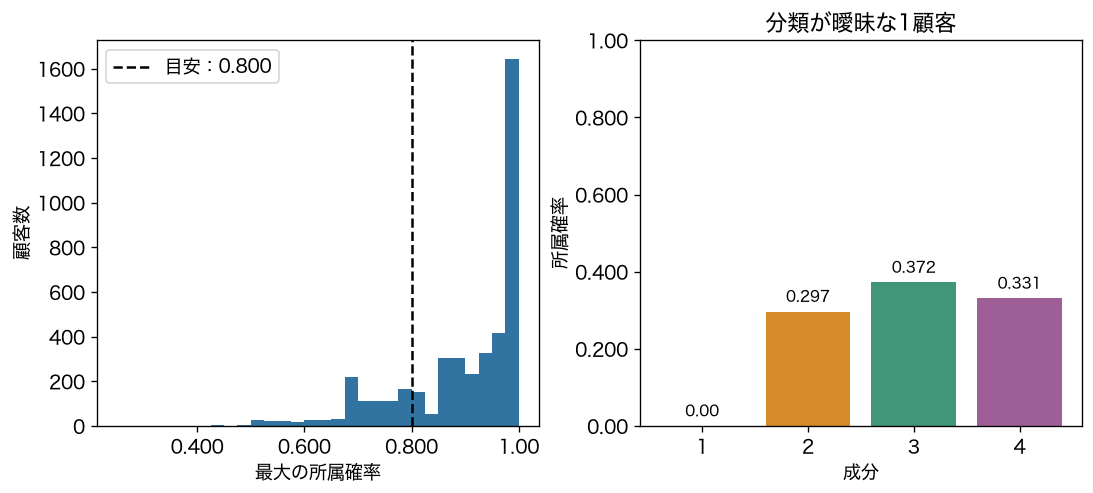

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6.30), sharex=True, sharey=True,
                         layout="constrained")
for k, ax in enumerate(axes.flat):
    dots = ax.scatter(Z[:, 0], Z[:, 1], c=proba[:, k], cmap="viridis",
                      vmin=0, vmax=1, s=8)
    ax.set(title=f"成分 {k + 1}", xlabel="総支出額：対数変換・標準化後",
           ylabel="注文回数：対数変換・標準化後")
fig.colorbar(dots, ax=axes, label="所属確率", format=tick3, shrink=0.800)
save_svg(fig, "05_membership_maps.svg")

# 最大の所属確率が低い顧客を1人選び、4成分への確率を確認する。
boundary = int(np.argmin(max_probability))
threshold = 0.800
pprint({"最大所属確率の中央値": sig3(np.median(max_probability)),
        "最大所属確率が0.800未満の割合（%）": sig3(100 * np.mean(max_probability < threshold))})
print("分類が曖昧な1顧客の所属確率（成分1〜4）")
pprint(proba[boundary])

fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
axes[0].hist(max_probability, bins=np.linspace(0.250, 1, 31), color=colors[0])
axes[0].axvline(threshold, color="black", linestyle="--", label="目安：0.800")
axes[0].set(xlabel="最大の所属確率", ylabel="顧客数")
axes[0].set_xticks([0.400, 0.600, 0.800, 1])
axes[0].xaxis.set_major_formatter(tick3)
axes[0].legend()
axes[1].bar(segments, proba[boundary], color=colors)
axes[1].set(xlabel="成分", ylabel="所属確率", xticks=segments, ylim=(0, 1),
            title="分類が曖昧な1顧客")
axes[1].yaxis.set_major_formatter(tick3)
for k, probability in zip(segments, proba[boundary]):
    axes[1].text(k, probability + 0.0250, sig3(probability), ha="center", fontsize=9)
save_svg(fig, "06_membership_uncertainty.svg")

図6の最大所属確率の中央値は0.944で、0.800未満の顧客は20.8%である。縦線の0.800は比較用の目安で、一般的な基準ではない。また、この確率はモデル上の所属の確かさであり、クーポンへの反応確率ではない。高い確率でも、顧客の心理や価値観が確定したとはいえない。

## 5. 分類結果を施策の案にする

本章では、低支出・単発中心の層には2回目購入の促進、中支出・リピート層には関連カテゴリの提案、高支出・高頻度層には関係維持を候補に挙げている。これらは観測した行動から考えた案であり、効果を確認した結果ではない。

このデータには卸売業者も多く含まれる。高支出の顧客については、法人・個人の区分や購入商品の構成も確認する。境界にいる顧客は対象を一律に決めず、複数の提案を比較する余地がある。

施策の検証では、各セグメント内で対象者を無作為に分け、施策を行う群と行わない群の再購入率、粗利、配信停止率などを比較する。差がなければ施策内容や特徴量、クラスタ数を見直す。分類の見た目より、この確認まで進められることが重要だと考える。

## 結論

この記事では、購買履歴を前処理し、k-meansとGMMで顧客を分類して、施策の対象を検討する流れを紹介した。

k-meansでは購入規模の違いを整理し、GMMでは所属確率から分類の曖昧さも確認する。どちらも、結果を元の単位で読み直し、施策の効果は別に検証する必要がある。

[本書の第2章](https://gihyo.jp/book/2026/978-4-297-16025-8)では、特徴量の選び方、分類結果の詳しい比較、顧客像の言語化まで扱っている。実装全体は[サポートページ](https://github.com/gihyo-book/marketing_science_book)を参照できる。

参考文献：D. Chen, [Online Retail](https://doi.org/10.24432/C5BW33), UCI, 2015（[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)）。本記事では書籍用CSVを条件で抽出し、顧客単位に集計した。理論の参考はC. M. Bishop『パターン認識と機械学習』（丸善出版、2012）である。